# 01 · Comprensión de los datos (CRISP-DM fase 2)

**Prerrequisito del Sprint 2.** Al revisar el proyecto, la preparación de datos del Sprint 1 no existía, así que se hace aquí,
separada del modelado. En este cuaderno solo se **mira** el dataset; no se modifica nada.

Dataset: Kaggle *Face Recognition Dataset* (vasukipatel), en `data/raw/Dataset/` (ignorado por git).

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
from PIL import Image
from src import config as C, data as D
C.FIGS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "axes.axisbelow": True})
SERIES = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}  # slots categoricos 1-3
print("Semilla:", C.SEED)

Semilla: 42


## 1. Estructura y CSV

In [2]:
df = D.load_index()
print("Columnas del CSV:", list(pd.read_csv(C.CSV_PATH).columns))
print("Filas del CSV:", len(df))
faces = set(os.listdir(C.FACES_DIR))
orig = {f: p for p in os.listdir(C.ORIGINALS_DIR) for f in os.listdir(C.ORIGINALS_DIR / p)}
print("Archivos en Faces:", len(faces), "| en Original Images:", len(orig), "| carpetas de personas:", len(set(orig.values())))
print("CSV == Faces:", set(df.filename) == faces, "| Faces == Originals (nombres):", faces == set(orig))
print("label == prefijo del nombre:", (df.filename.str.rsplit("_", n=1).str[0] == df.person).all())
print("Etiqueta del CSV == carpeta del original:", all(orig[f] == p for f, p in zip(df.filename, df.person)))

Columnas del CSV: ['id', 'label']
Filas del CSV: 2562
Archivos en Faces: 2562 | en Original Images: 2562 | carpetas de personas: 31
CSV == Faces: True | Faces == Originals (nombres): True
label == prefijo del nombre: True
Etiqueta del CSV == carpeta del original: True


## 2. Imágenes por persona

Identidades: 31 | total: 2562 | min 30 (Kashyap) | max 120 (Brad Pitt) | media 82.6 | mediana 80


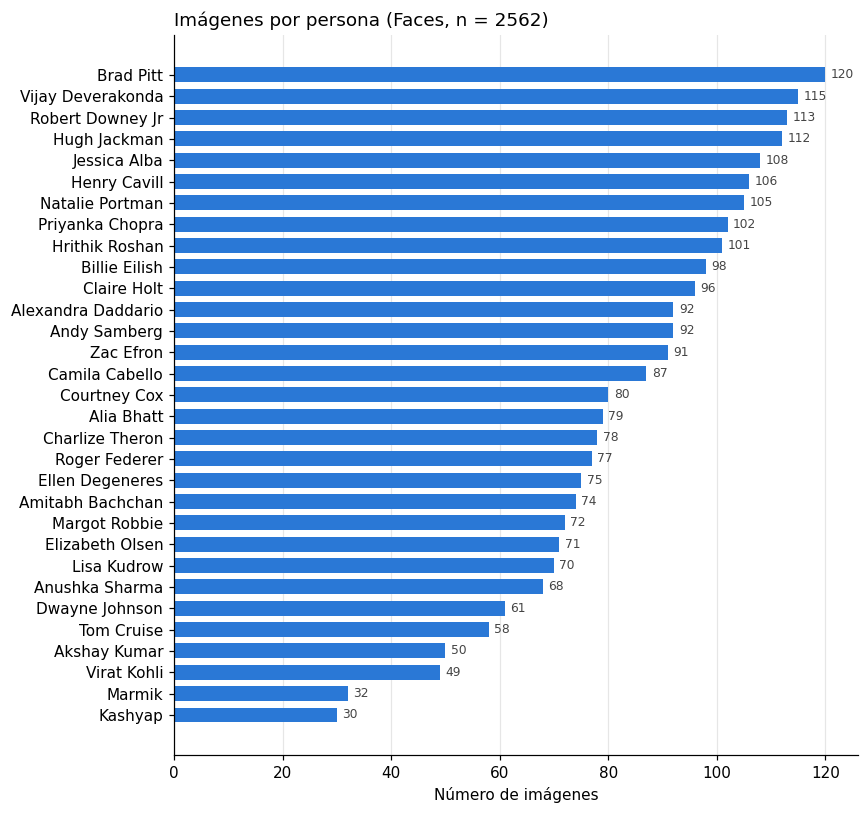

,n_imagenes
person,
Brad Pitt,120
Vijay Deverakonda,115
Robert Downey Jr,113
Hugh Jackman,112
Jessica Alba,108
Henry Cavill,106
Natalie Portman,105
Priyanka Chopra,102
Hrithik Roshan,101


In [3]:
cnt = df.person.value_counts().sort_values()
print(f"Identidades: {cnt.size} | total: {cnt.sum()} | min {cnt.min()} ({cnt.idxmin()}) | max {cnt.max()} ({cnt.idxmax()}) | media {cnt.mean():.1f} | mediana {cnt.median():.0f}")
fig, ax = plt.subplots(figsize=(8, 7.5))
ax.barh(cnt.index, cnt.values, color="#2a78d6", height=0.7)
for y, v in enumerate(cnt.values):
    ax.text(v + 1, y, str(v), va="center", fontsize=8, color="#444")
ax.set_xlabel("Número de imágenes"); ax.set_title("Imágenes por persona (Faces, n = %d)" % cnt.sum(), loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(C.FIGS / "01_imagenes_por_persona.png"); plt.show()
cnt.sort_values(ascending=False).rename("n_imagenes").to_frame()

## 3. Tamaños y formato

In [4]:
fsz = pd.Series([Image.open(p).size for p in df.path]).value_counts()
fmode = pd.Series([Image.open(p).mode for p in df.path]).value_counts()
print("Faces - tamaños:", fsz.to_dict(), "| modos:", fmode.to_dict())
osz = np.array([Image.open(C.ORIGINALS_DIR / p / f).size for f, p in zip(df.filename, df.person)])
print("Originals - ancho min/mediana/max:", osz[:,0].min(), int(np.median(osz[:,0])), osz[:,0].max(),
      "| alto:", osz[:,1].min(), int(np.median(osz[:,1])), osz[:,1].max())

Faces - tamaños: {(160, 160): 2562} | modos: {'RGB': 2562}


Originals - ancho min/mediana/max: 216 967 5760 | alto: 200 891 5568


## 4. ¿`Faces` son recortes de `Original Images`?
Se muestran pares con el mismo nombre de archivo (original a la izquierda, recorte a la derecha).

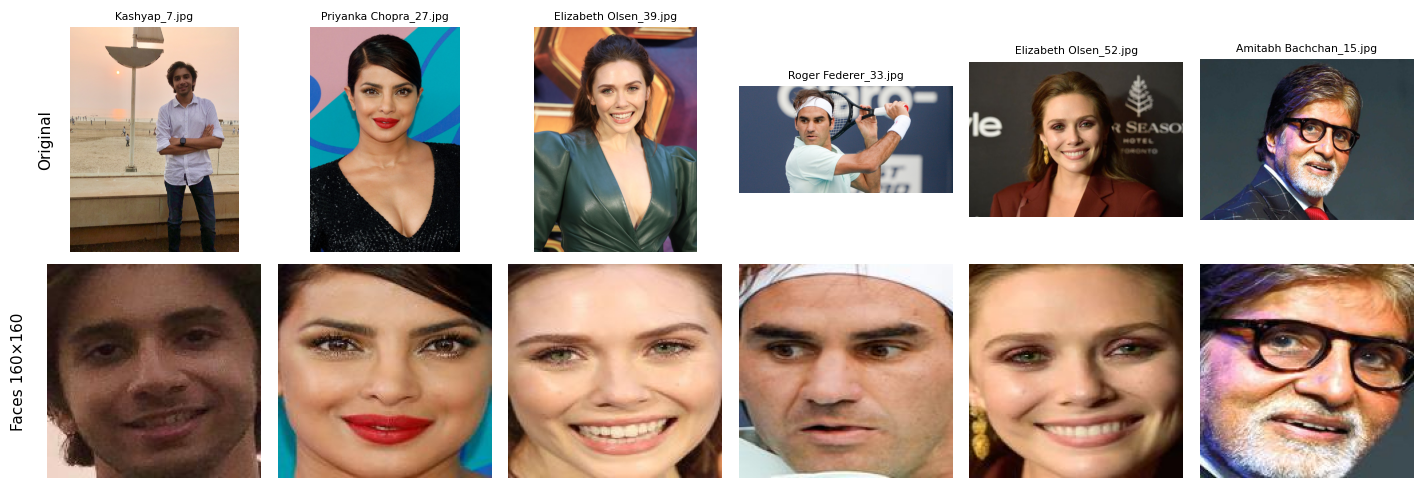

In [5]:
rng = np.random.default_rng(C.SEED)
pick = rng.choice(df.index, 6, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(13, 4.6))
for k, i in enumerate(pick):
    r = df.loc[i]
    axes[0, k].imshow(D.read_rgb(C.ORIGINALS_DIR / r.person / r.filename)); axes[0, k].set_title(r.filename, fontsize=7)
    axes[1, k].imshow(D.read_rgb(r.path))
for a in axes.ravel(): a.axis("off")
axes[0,0].text(-0.1, .5, "Original", transform=axes[0,0].transAxes, rotation=90, va="center", ha="right")
axes[1,0].text(-0.1, .5, "Faces 160×160", transform=axes[1,0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout(); plt.savefig(C.FIGS / "01_original_vs_faces.png"); plt.show()

**Conclusión:** cada imagen de `Faces` es un recorte ajustado del rostro (frente y mentón parcialmente cortados) de la imagen
original con el mismo nombre. Son las **mismas fotografías**, así que usar ambas carpetas filtraría información entre conjuntos.
Se usa **solo `Faces`**. Como ya viene recortado a 160×160, en esta etapa **no hace falta detectar rostros**; la detección solo
se necesitará para los fotogramas de video (tarea 2.6), y allí el recorte debe imitar este encuadre ajustado.

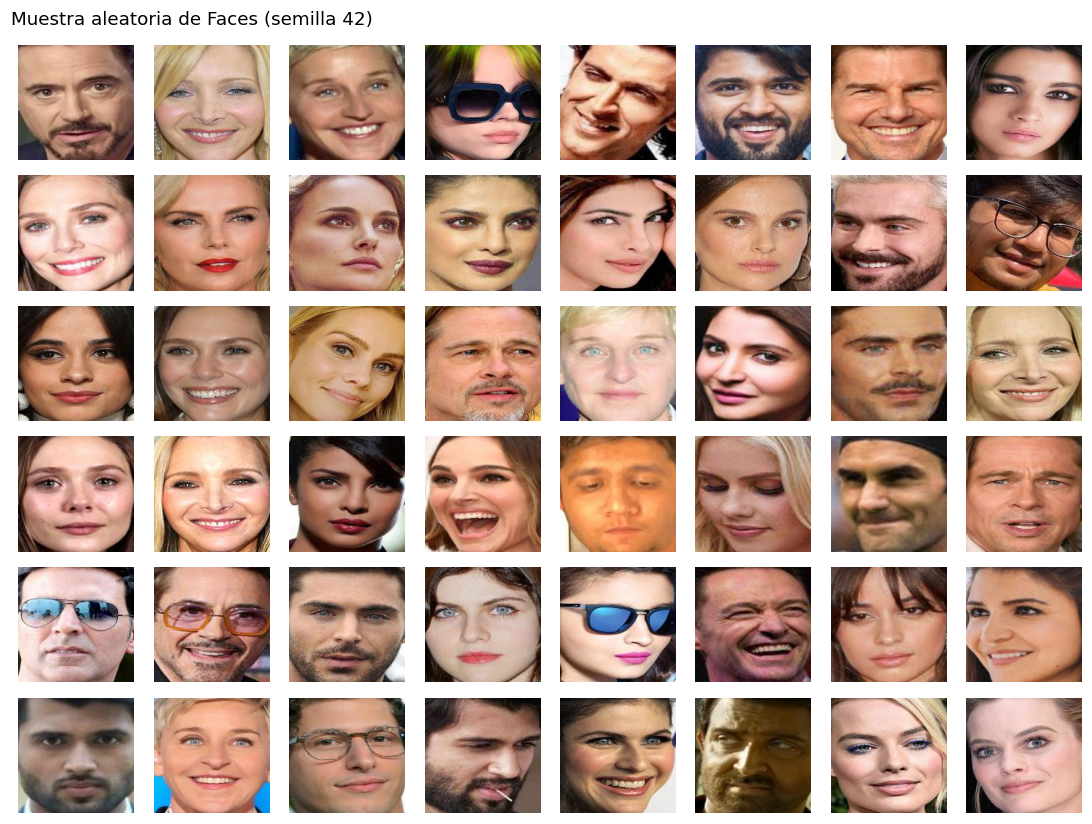

In [6]:
grid = [D.read_rgb(p) for p in df.sample(48, random_state=C.SEED).path]
fig, axes = plt.subplots(6, 8, figsize=(10, 7.6))
for a, im in zip(axes.ravel(), grid): a.imshow(im); a.axis("off")
plt.suptitle("Muestra aleatoria de Faces (semilla 42)", x=0.01, ha="left"); plt.tight_layout()
plt.savefig(C.FIGS / "01_muestra_faces.png"); plt.show()

## 5. Duplicados y casi duplicados

1. **Exactos**: mismo hash MD5.
2. **Casi idénticos**: se probó primero dHash (64 bits), pero con caras alineadas es demasiado grueso: a distancia 3 ya empareja
   fotos *distintas* de la misma persona. Se usa en su lugar la **correlación de píxeles** de las imágenes reducidas a 32×32 en color
   (también contra el espejo horizontal).

In [7]:
md5 = df.path.map(D.md5_of)
dup = df.assign(md5=md5).groupby("md5").filter(lambda g: len(g) > 1).groupby("md5").filename.apply(list)
print("Grupos de duplicados exactos (MD5):", len(dup)); [print("  ", v) for v in dup]
S = D.pixel_similarity(df.path.tolist())
iu = np.triu_indices(len(df), 1); c = S[iu]; same = df.person.values[iu[0]] == df.person.values[iu[1]]
tab = pd.DataFrame([(t, int((c >= t).sum()), int(((c >= t) & same).sum()), int(((c >= t) & ~same).sum()))
                    for t in [0.99, 0.97, 0.95, 0.93, 0.92, 0.90, 0.88]],
                   columns=["umbral_corr", "pares", "misma_persona", "distinta_persona"])
tab

Grupos de duplicados exactos (MD5): 5
   ['Natalie Portman_92.jpg', 'Natalie Portman_93.jpg']
   ['Hugh Jackman_82.jpg', 'Hugh Jackman_83.jpg']
   ['Courtney Cox_23.jpg', 'Courtney Cox_45.jpg']
   ['Courtney Cox_10.jpg', 'Courtney Cox_9.jpg']
   ['Henry Cavill_25.jpg', 'Henry Cavill_5.jpg']


,umbral_corr,pares,misma_persona,distinta_persona
0,0.99,9,9,0
1,0.97,30,30,0
2,0.95,40,40,0
3,0.93,65,64,1
4,0.92,82,81,1
5,0.90,173,147,26
6,0.88,516,324,192


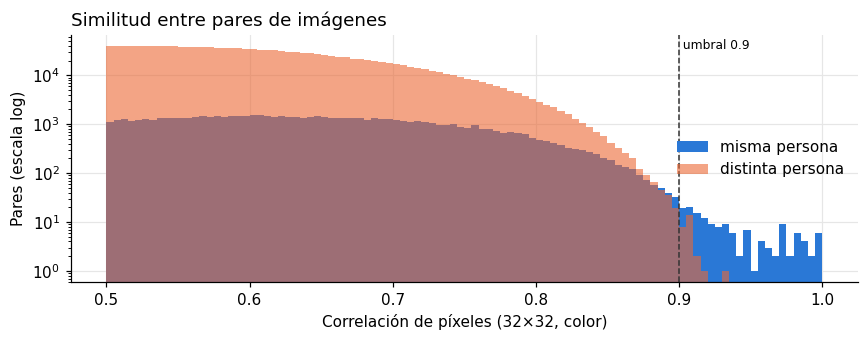

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.linspace(0.5, 1, 101)
ax.hist(c[same], bins=bins, color="#2a78d6", label="misma persona", log=True)
ax.hist(c[~same], bins=bins, color="#eb6834", alpha=0.6, label="distinta persona", log=True)
ax.axvline(C.DUP_CORR_THRESHOLD, color="#333", lw=1, ls="--"); ax.text(C.DUP_CORR_THRESHOLD, ax.get_ylim()[1]*0.5, f" umbral {C.DUP_CORR_THRESHOLD}", fontsize=8)
ax.set_xlabel("Correlación de píxeles (32×32, color)"); ax.set_ylabel("Pares (escala log)"); ax.legend(frameon=False)
ax.set_title("Similitud entre pares de imágenes", loc="left"); plt.tight_layout()
plt.savefig(C.FIGS / "01_hist_similitud_pares.png"); plt.show()

Pares de la misma persona, para elegir el umbral a ojo: (a) los más parecidos; (b) los que están alrededor del umbral.

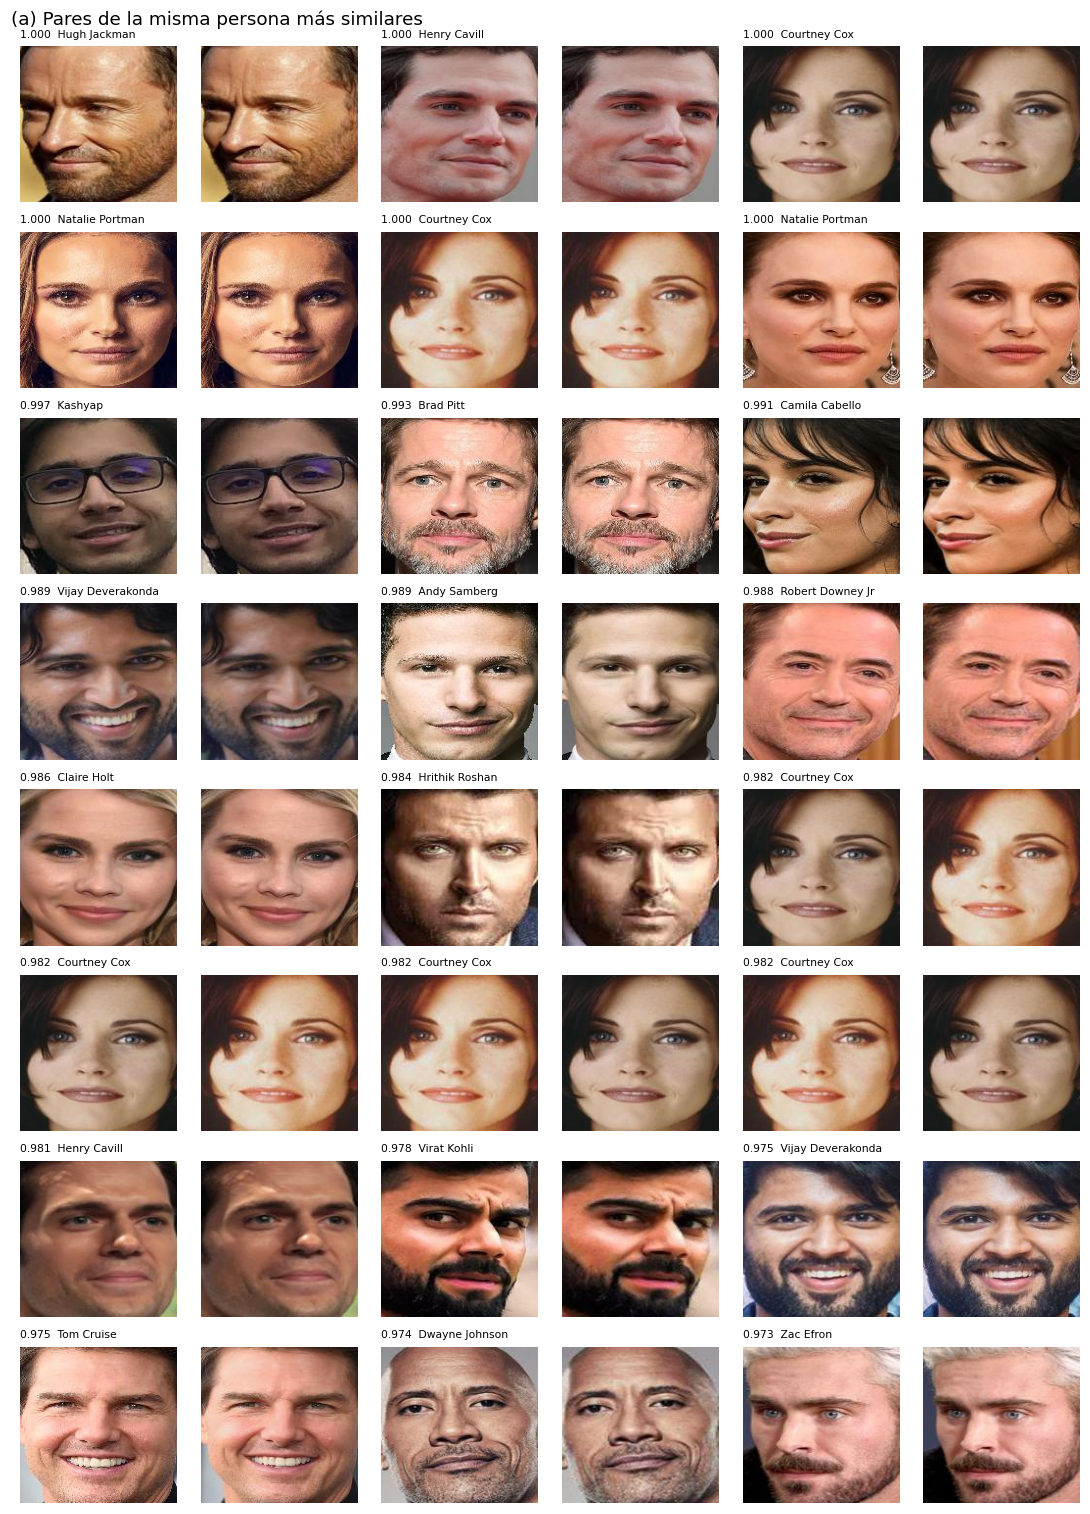

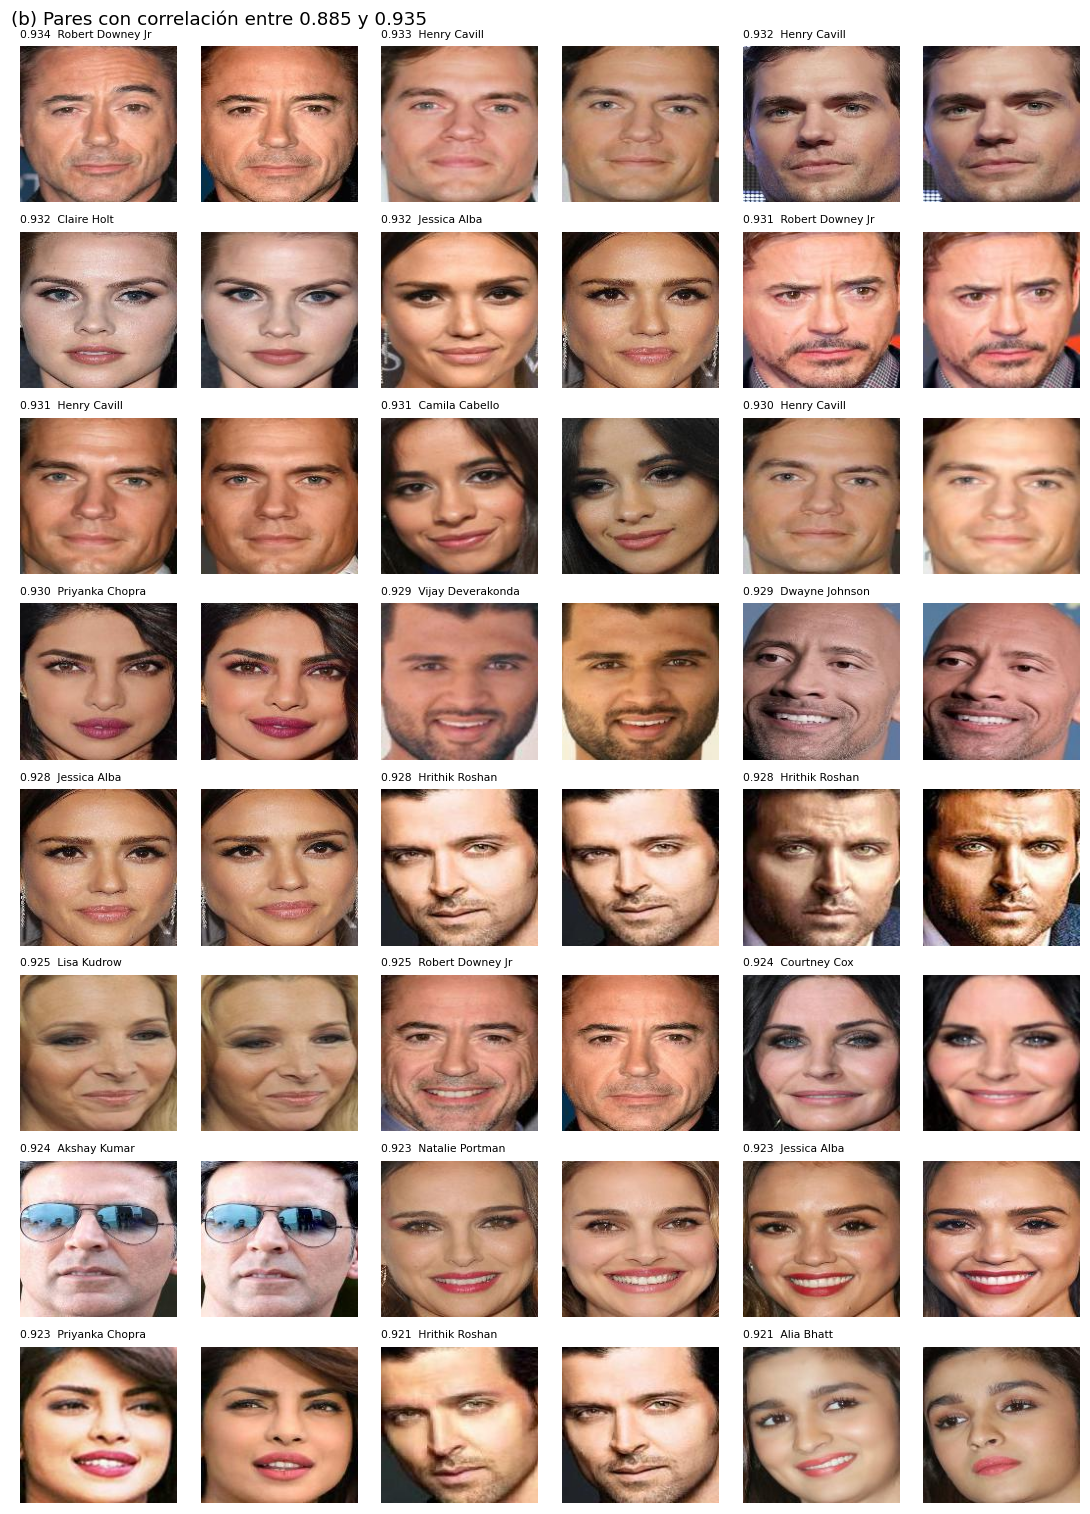

In [9]:
def montage(ks, fname, title):
    fig, axes = plt.subplots(8, 6, figsize=(10, 14))
    for ax2, k in zip(axes.reshape(-1, 2), ks):
        i, j = iu[0][k], iu[1][k]
        ax2[0].imshow(D.read_rgb(df.path[i])); ax2[1].imshow(D.read_rgb(df.path[j]))
        ax2[0].set_title(f"{c[k]:.3f}  {df.person[i]}", fontsize=7, loc="left")
    for a in axes.ravel(): a.axis("off")
    plt.suptitle(title, x=0.01, ha="left"); plt.tight_layout(); plt.savefig(C.FIGS / fname); plt.show()
srt = [k for k in np.argsort(-c) if same[k]]
montage(srt[:24], "01_pares_mas_similares.png", "(a) Pares de la misma persona más similares")
montage([k for k in srt if 0.885 <= c[k] < 0.935][:24], "01_pares_cerca_umbral.png", "(b) Pares con correlación entre 0.885 y 0.935")

In [10]:
rows = []
for t in [0.92, 0.90, 0.89, 0.88]:
    g = D.group_near_duplicates(df, t)[0].groupby("group_id").size()
    rows.append((t, int((g > 1).sum()), int(g[g > 1].sum()), int(g.max())))
pd.DataFrame(rows, columns=["umbral", "grupos_con_>1", "imagenes_agrupadas", "grupo_mas_grande"])

,umbral,grupos_con_>1,imagenes_agrupadas,grupo_mas_grande
0,0.92,69,146,4
1,0.90,93,230,12
2,0.89,106,291,24
3,0.88,121,364,33


**Decisión: umbral 0.90** (solo se agrupan pares de la **misma persona**).
- Revisando las figuras (a) y (b): por encima de ~0.93 casi todos los pares son la misma foto (recompresión, variante de color, recorte algo distinto).
  Entre 0.90 y 0.93 hay mezcla: algunos son la misma foto (p. ej. pares de Courtney Cox, Amitabh Bachchan) y otros son fotos distintas pero muy parecidas.
- Agrupar de más solo cuesta un poco de equilibrio en la división; agrupar de menos filtraría datos entre conjuntos. Por eso se elige un umbral conservador.
- No se baja de 0.90 porque las cadenas (si A≈B y B≈C, todo es un grupo) crecen rápido: con 0.89 ya aparece un grupo de 24 fotos distintas.
- Limitación: la correlación de píxeles no detecta la misma sesión fotográfica con otra pose. El riesgo residual se cuantifica en el cuaderno 02.

## 6. Sesgo del dataset: famosos

- 29 de las 31 identidades son **celebridades**; **Marmik** y **Kashyap** parecen personas no famosas (y son las que tienen menos fotos: 32 y 30).
- Los modelos preentrenados de rostros (FaceNet entrenado en VGGFace2, ArcFace en MS1M, etc.) muy probablemente vieron fotos de estas
  celebridades. Los resultados de transferencia de aprendizaje pueden salir **optimistas**. Por eso Marmik queda como registrada y
  Kashyap como impostora de prueba, y sus resultados se reportarán por separado.
- Son fotos de prensa/alfombra roja: bien iluminadas, casi todas frontales, a veces retocadas o con maquillaje. Hay gafas (de sol en algunos casos).
  Una cámara web real (contraluz, pose, desenfoque) será más difícil.
- Hay desbalance entre identidades (30 a 120 imágenes).